In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import os

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [1]:
import pandas as pd
import numpy as np

print("Welcome to FinWise AI!")
print("Financial Analysis Engine Initialized.")

Welcome to FinWise AI!
Financial Analysis Engine Initialized.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

print("FinWise AI initialized successfully!")

FinWise AI initialized successfully!


In [3]:
data = {
    "Date": [
        "2026-11-01", "2026-11-02",
        "2026-11-03", "2026-11-04",
        "2026-11-05", "2026-11-06",
        "2026-11-07", "2026-11-08",
        "2026-11-09", "2026-11-10"
    ],

    "Description": [
        "Salary", "Groceries", "Electricity",
        "Restaurant", "Petrol", "Shopping",
        "Mobile Recharge", "Movie",
        "Freelance Income", "Food Delivery"
    ],

    "Category": [
        "Income", "Food", "Bills",
        "Food", "Transport", "Shopping",
        "Bills", "Entertainment", "Income", "Food"
    ],

    "Amount": [
        30000, 2000, 1500, 800, 1000,
        3000, 500, 600, 5000, 400
    ],

    "Type": [
        "Income", "Expense", "Expense",
        "Expense", "Expense", "Expense",
        "Expense", "Expense", "Income", "Expense"
    ]
}

df = pd.DataFrame(data)

df["Date"] = pd.to_datetime(df["Date"])

df

,Date,Description,Category,Amount,Type
0,2026-11-01,Salary,Income,30000,Income
1,2026-11-02,Groceries,Food,2000,Expense
2,2026-11-03,Electricity,Bills,1500,Expense
3,2026-11-04,Restaurant,Food,800,Expense
4,2026-11-05,Petrol,Transport,1000,Expense
5,2026-11-06,Shopping,Shopping,3000,Expense
6,2026-11-07,Mobile Recharge,Bills,500,Expense
7,2026-11-08,Movie,Entertainment,600,Expense
8,2026-11-09,Freelance Income,Income,5000,Income
9,2026-11-10,Food Delivery,Food,400,Expense


In [4]:
income = df[df["Type"] == "Income"]["Amount"].sum()

expenses = df[df["Type"] == "Expense"]["Amount"].sum()

savings = income - expenses

print("Total Income: ₹", income)
print("Total Expenses: ₹", expenses)
print("Remaining Balance: ₹", savings)

Total Income: ₹ 35000
Total Expenses: ₹ 9800
Remaining Balance: ₹ 25200


In [5]:
# Category-wise Expense Analysis

expense_df = df[df["Type"] == "Expense"]

category_expenses = (
    expense_df.groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Category-wise Expenses:")
print(category_expenses)

Category-wise Expenses:
Category
Food             3200
Shopping         3000
Bills            2000
Transport        1000
Entertainment     600
Name: Amount, dtype: int64


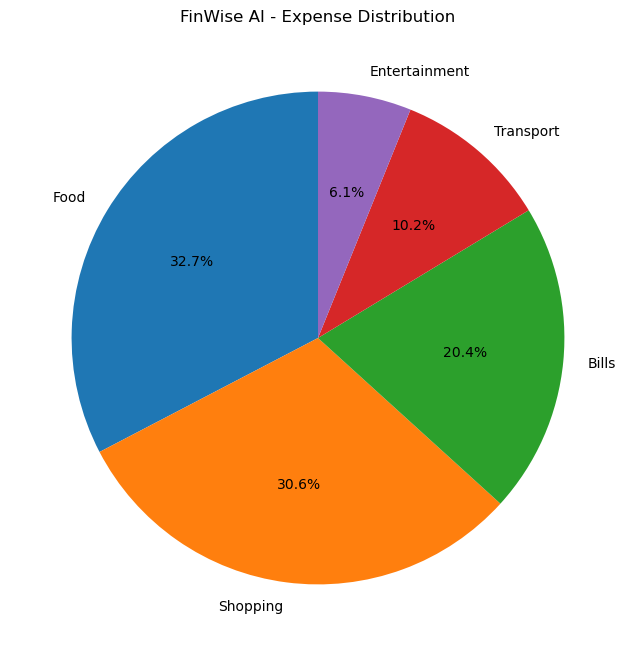

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

plt.pie(
    category_expenses,
    labels=category_expenses.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("FinWise AI - Expense Distribution")

plt.show()

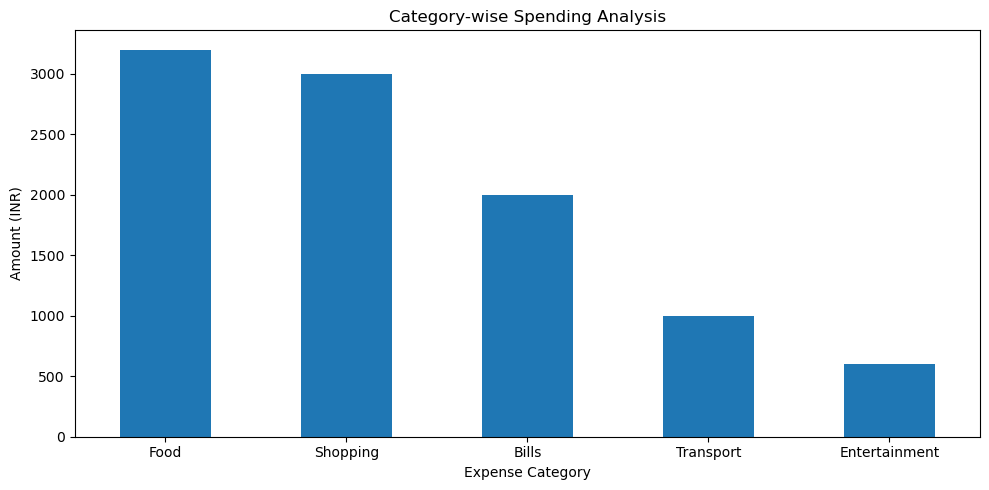

In [7]:
plt.figure(figsize=(10, 5))

category_expenses.plot(
    kind="bar",
    title="Category-wise Spending Analysis"
)

plt.xlabel("Expense Category")
plt.ylabel("Amount (INR)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
highest_category = category_expenses.idxmax()

highest_amount = category_expenses.max()

total_expenses = expense_df["Amount"].sum()

percentage = (highest_amount / total_expenses) * 100

print("FINWISE AI - FINANCIAL INSIGHTS")

print(f"Highest spending category: {highest_category}")

print(f"Amount spent: Rs. {highest_amount}")

print(f"Percentage of total expenses: {percentage:.2f}%")

FINWISE AI - FINANCIAL INSIGHTS
Highest spending category: Food
Amount spent: Rs. 3200
Percentage of total expenses: 32.65%


In [9]:
monthly_budget = {
    "Food": 4000,
    "Shopping": 2500,
    "Bills": 2500,
    "Transport": 1500,
    "Entertainment": 1000
}

In [10]:
budget_df = pd.DataFrame({
    "Category": category_expenses.index,
    "Spent": category_expenses.values
})

budget_df["Budget"] = budget_df["Category"].map(monthly_budget)
budget_df["Remaining"] = budget_df["Budget"] - budget_df["Spent"]

budget_df["Status"] = np.where(
    budget_df["Remaining"] < 0,
    "Over Budget",
    "Within Budget"
)

budget_df["Usage_Percent"] = (
    budget_df["Spent"] / budget_df["Budget"] * 100
).round(2)

budget_df

,Category,Spent,Budget,Remaining,Status,Usage_Percent
0,Food,3200,4000,800,Within Budget,80.00
1,Shopping,3000,2500,-500,Over Budget,120.00
2,Bills,2000,2500,500,Within Budget,80.00
3,Transport,1000,1500,500,Within Budget,66.67
4,Entertainment,600,1000,400,Within Budget,60.00


In [11]:
print("FINWISE AI - BUDGET REPORT\n")

for _, row in budget_df.iterrows():

    if row["Remaining"] < 0:
        print(
            f"Warning: {row['Category']} is over budget "
            f"by Rs. {abs(row['Remaining']):,.0f}"
        )

    else:
        print(
            f"{row['Category']}: Rs. {row['Remaining']:,.0f} remaining"
        )

FINWISE AI - BUDGET REPORT

Food: Rs. 800 remaining
Bills: Rs. 500 remaining
Transport: Rs. 500 remaining
Entertainment: Rs. 400 remaining


In [12]:
def analyze_expenses(df):

    expense_df = df[df["Type"] == "Expense"]

    total_expenses = expense_df["Amount"].sum()

    category_expenses = (
        expense_df.groupby("Category")["Amount"]
        .sum()
        .sort_values(ascending=False)
    )

    return {
        "total_expenses": total_expenses,
        "category_expenses": category_expenses.to_dict()
    }

In [13]:
def calculate_savings(df):

    income = df[df["Type"] == "Income"]["Amount"].sum()

    expenses = df[df["Type"] == "Expense"]["Amount"].sum()

    savings = income - expenses

    savings_rate = (savings / income * 100) if income > 0 else 0

    return {
        "total_income": income,
        "total_expenses": expenses,
        "total_savings": savings,
        "savings_rate": round(savings_rate, 2)
    }

In [14]:
expense_result = analyze_expenses(df)

savings_result = calculate_savings(df)

print("FINWISE AI - EXPENSE ANALYSIS")
print(expense_result)

print("\nFINWISE AI - SAVINGS ANALYSIS")
print(savings_result)

FINWISE AI - EXPENSE ANALYSIS
{'total_expenses': np.int64(9800), 'category_expenses': {'Food': 3200, 'Shopping': 3000, 'Bills': 2000, 'Transport': 1000, 'Entertainment': 600}}

FINWISE AI - SAVINGS ANALYSIS
{'total_income': np.int64(35000), 'total_expenses': np.int64(9800), 'total_savings': np.int64(25200), 'savings_rate': np.float64(72.0)}


In [15]:
monthly_data = {
    "Date": [
        "2026-10-01", "2026-10-05", "2026-10-10",
        "2026-10-15", "2026-11-01", "2026-11-05",
        "2026-11-10", "2026-11-15"
    ],
    "Description": [
        "Salary", "Groceries", "Shopping", "Transport",
        "Salary", "Groceries", "Shopping", "Transport"
    ],
    "Category": [
        "Income", "Food", "Shopping", "Transport",
        "Income", "Food", "Shopping", "Transport"
    ],
    "Amount": [
        30000, 4000, 3000, 1500,
        35000, 5000, 4500, 2000
    ],
    "Type": [
        "Income", "Expense", "Expense", "Expense",
        "Income", "Expense", "Expense", "Expense"
    ]
}

monthly_df = pd.DataFrame(monthly_data)

monthly_df["Date"] = pd.to_datetime(monthly_df["Date"])

monthly_df

,Date,Description,Category,Amount,Type
0,2026-10-01,Salary,Income,30000,Income
1,2026-10-05,Groceries,Food,4000,Expense
2,2026-10-10,Shopping,Shopping,3000,Expense
3,2026-10-15,Transport,Transport,1500,Expense
4,2026-11-01,Salary,Income,35000,Income
5,2026-11-05,Groceries,Food,5000,Expense
6,2026-11-10,Shopping,Shopping,4500,Expense
7,2026-11-15,Transport,Transport,2000,Expense


In [16]:
def compare_months(df):

    data = df.copy()

    data["Month"] = data["Date"].dt.strftime("%Y-%m")

    monthly_summary = data.pivot_table(
        index="Month",
        columns="Type",
        values="Amount",
        aggfunc="sum",
        fill_value=0
    )

    monthly_summary["Savings"] = (
        monthly_summary.get("Income", 0)
        - monthly_summary.get("Expense", 0)
    )

    return monthly_summary

In [17]:
comparison = compare_months(monthly_df)

print("FINWISE AI - MONTHLY COMPARISON")

comparison

FINWISE AI - MONTHLY COMPARISON


Type,Expense,Income,Savings
Month,,,
2026-10,8500,30000,21500
2026-11,11500,35000,23500


In [18]:
if len(comparison) >= 2:

    previous_month = comparison.iloc[-2]
    current_month = comparison.iloc[-1]

    expense_change = (
        current_month["Expense"] - previous_month["Expense"]
    )

    print("\nMONTHLY FINANCIAL INSIGHT")

    if expense_change > 0:
        print(f"Your expenses increased by Rs. {expense_change:,.0f}.")

    elif expense_change < 0:
        print(f"Your expenses decreased by Rs. {abs(expense_change):,.0f}.")

    else:
        print("Your expenses remained unchanged.")


MONTHLY FINANCIAL INSIGHT
Your expenses increased by Rs. 3,000.


In [19]:
def savings_calculator(income, expenses, savings_goal):

    monthly_savings = income - expenses

    if monthly_savings <= 0:
        return {
            "monthly_savings": monthly_savings,
            "savings_rate": 0,
            "months_required": None,
            "message": "You need to reduce expenses or increase income."
        }

    savings_rate = (monthly_savings / income) * 100 if income > 0 else 0

    months_required = (
        int(np.ceil(savings_goal / monthly_savings))
    )

    return {
        "monthly_savings": monthly_savings,
        "savings_rate": round(savings_rate, 2),
        "months_required": months_required,
        "message": "Savings goal is achievable at this monthly savings rate."
    }

In [20]:
result = savings_calculator(
    income=35000,
    expenses=15000,
    savings_goal=100000
)

print("FINWISE AI - SAVINGS GOAL REPORT\n")

for key, value in result.items():
    print(f"{key}: {value}")

FINWISE AI - SAVINGS GOAL REPORT

monthly_savings: 20000
savings_rate: 57.14
months_required: 5
message: Savings goal is achievable at this monthly savings rate.


In [21]:
savings_calculator(
    income=25000,
    expenses=27000,
    savings_goal=50000
)

{'monthly_savings': -2000,
 'savings_rate': 0,
 'months_required': None,
 'message': 'You need to reduce expenses or increase income.'}

In [22]:
def generate_financial_insights(df):

    income = df[df["Type"] == "Income"]["Amount"].sum()
    expense_df = df[df["Type"] == "Expense"]

    expenses = expense_df["Amount"].sum()
    savings = income - expenses

    insights = []

    # Income and expense analysis
    if income > 0:
        savings_rate = (savings / income) * 100
    else:
        savings_rate = 0

    insights.append(f"Total income: Rs. {income:,.2f}")
    insights.append(f"Total expenses: Rs. {expenses:,.2f}")
    insights.append(f"Total savings: Rs. {savings:,.2f}")

    # Savings analysis
    if savings < 0:
        insights.append("Warning: Your expenses exceed your income.")

    elif savings_rate < 20:
        insights.append("Your savings rate is low. Consider reducing expenses.")

    else:
        insights.append("Your savings rate is healthy based on this simple threshold.")

    # Category analysis
    if not expense_df.empty:

        category_expenses = (
            expense_df.groupby("Category")["Amount"].sum()
        )

        highest_category = category_expenses.idxmax()
        highest_amount = category_expenses.max()

        insights.append(
            f"Your highest spending category is {highest_category}, "
            f"with Rs. {highest_amount:,.2f} spent."
        )

    return insights

In [23]:
financial_insights = generate_financial_insights(df)

print("FINWISE AI - FINANCIAL INSIGHTS\n")

for insight in financial_insights:
    print("-", insight)

FINWISE AI - FINANCIAL INSIGHTS

- Total income: Rs. 35,000.00
- Total expenses: Rs. 9,800.00
- Total savings: Rs. 25,200.00
- Your savings rate is healthy based on this simple threshold.
- Your highest spending category is Food, with Rs. 3,200.00 spent.


In [24]:
test_data = pd.DataFrame({
    "Category": ["Income", "Food", "Shopping", "Bills"],
    "Amount": [20000, 8000, 7000, 6000],
    "Type": ["Income", "Expense", "Expense", "Expense"]
})

test_insights = generate_financial_insights(test_data)

for insight in test_insights:
    print("-", insight)

- Total income: Rs. 20,000.00
- Total expenses: Rs. 21,000.00
- Total savings: Rs. -1,000.00
- Warning: Your expenses exceed your income.
- Your highest spending category is Food, with Rs. 8,000.00 spent.


In [3]:
import os

os.makedirs("data", exist_ok=True)

transactions = pd.DataFrame({
    "Date": [
        "2026-10-01", "2026-10-02", "2026-10-03",
        "2026-10-04", "2026-10-05", "2026-10-06",
        "2026-11-01", "2026-11-02", "2026-11-03",
        "2026-11-04", "2026-11-05", "2026-11-06"
    ],
    "Description": [
        "Salary", "Groceries", "Electricity", "Restaurant",
        "Petrol", "Shopping", "Salary", "Groceries",
        "Electricity", "Food Delivery", "Petrol", "Shopping"
    ],
    "Category": [
        "Income", "Food", "Bills", "Food", "Transport", "Shopping",
        "Income", "Food", "Bills", "Food", "Transport", "Shopping"
    ],
    "Amount": [
        30000, 2500, 1500, 1000, 1200, 2500,
        35000, 3000, 1800, 1200, 1500, 3000
    ],
    "Type": [
        "Income", "Expense", "Expense", "Expense",
        "Expense", "Expense", "Income", "Expense",
        "Expense", "Expense", "Expense", "Expense"
    ]
})

transactions["Date"] = pd.to_datetime(transactions["Date"])

transactions.to_csv("data/transactions.csv", index=False)

print("Transaction dataset created successfully!")

Transaction dataset created successfully!


In [4]:
print("Data folder exists:", os.path.exists("data"))
print("CSV file exists:", os.path.exists("data/transactions.csv"))

Data folder exists: True
CSV file exists: True


In [1]:
print("FINWISE AI - Python is working!")

FINWISE AI - Python is working!


In [2]:
from dotenv import load_dotenv
import os

load_dotenv(dotenv_path=r"C:\Users\User\FinWise-AI\.env", override=True)

api_key = os.getenv("GEMINI_API_KEY")

print("API key loaded:", bool(api_key))

API key loaded: False


In [6]:
from dotenv import load_dotenv
import os

load_dotenv(
    dotenv_path=r"C:\Users\User\FinWise-AI\.env",
    override=True
)

api_key = os.getenv("GEMINI_API_KEY")

print("API key loaded:", bool(api_key))

API key loaded: False


In [7]:
from dotenv import load_dotenv
import os

load_dotenv(
    r"C:\Users\User\FinWise-AI\.env",
    override=True
)

api_key = os.getenv("GEMINI_API_KEY")

print("API key loaded:", bool(api_key))

API key loaded: False


In [8]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in project folder:")
print(os.listdir(r"C:\Users\User\FinWise-AI"))

print("\nDoes .env exist?")
print(os.path.exists(r"C:\Users\User\FinWise-AI\.env"))

print("\nDoes env.txt exist?")
print(os.path.exists(r"C:\Users\User\FinWise-AI\env.txt"))

Current folder:
C:\Users\User\FinWise-AI

Files in project folder:
['.env.bz2', '.env.txt', '.ipynb_checkpoints', 'data', 'Untitled.ipynb', 'venv']

Does .env exist?
False

Does env.txt exist?
False


In [11]:
from dotenv import load_dotenv
import os

load_dotenv(
    dotenv_path=r"C:\Users\User\FinWise-AI\.env",
    override=True,
    encoding="utf-8"
)

api_key = os.getenv("GEMINI_API_KEY")

print("API key loaded:", bool(api_key))

API key loaded: True


In [12]:
from google import genai
import os

client = genai.Client(api_key=os.getenv("GEMINI_API_KEY"))

print("Gemini client connected successfully!")

Gemini client connected successfully!


In [13]:
response = client.models.generate_content(
    model="gemini-3.8-flash",
    contents="Explain the 50/30/20 budgeting rule in simple words."
)

print(response.text)

ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [ ]:
import time

for attempt in range(4):
    try:
        response = client.models.generate_content(
            model="gemini-3.8-flash",
            contents="Explain the 50/30/20 budgeting rule in simple words."
        )

        print(response.text)
        break

    except Exception as e:
        print(f"Attempt {attempt + 1} failed: {e}")

        if attempt < 3:
            wait_time = 10 * (2 ** attempt)
            print(f"Retrying in {wait_time} seconds...")
            time.sleep(wait_time)
        else:
            print("Gemini is still unavailable. Try again later.")

Attempt 1 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Retrying in 10 seconds...


In [1]:
response = client.models.generate_content(
    model="gemini-3.8-flash",
    contents="Explain the 50/30/20 budgeting rule in simple words."
)

print(response.text)

NameError: name 'client' is not defined

In [2]:
from google import genai
import os
from dotenv import load_dotenv

load_dotenv(
    r"C:\Users\User\FinWise-AI\.env",
    override=True
)

api_key = os.getenv("GEMINI_API_KEY")

client = genai.Client(api_key=api_key)

print("Gemini client connected successfully!")

Gemini client connected successfully!


In [3]:
response = client.models.generate_content(
    model="gemini-3.8-flash",
    contents="Explain the 50/30/20 budgeting rule in simple words."
)

print(response.text)

ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [4]:
for model in client.models.list():
    if "generateContent" in (model.supported_actions or []):
        print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3.1-flash-lite
models/gemini-3-pro-image
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/gemini-4-carbon
models/gemini-4-hydrogen
models/antigravity-preview-05-2026
models/antigravity-preview-09-2026
models/antigravity-preview-latest
models/deep-research-max-preview-04-2026
models/deep-research-preview-04-2026
models/deep-research-pro-preview-12-2025


In [5]:
response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents="Explain the 50/30/20 budgeting rule in simple words."
)

print(response.text)

ClientError: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://aistudio.google.com/docs/get-started).', 'status': 'NOT_FOUND'}}

In [6]:
response = client.models.generate_content(
    model="gemini-3.8-flash",
    contents="Explain the 50/30/20 budgeting rule in simple words."
)

print(response.text)

ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [7]:
response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents="Explain the 50/30/20 budgeting rule in simple words."
)

print(response.text)

The **50/30/20 rule** is a super simple way to manage your money without having to track every single penny you spend. 

Imagine you take your paycheck home, put it all in one big pile, and divide it into three buckets:

### 1. 50% for Needs (The "Must-Haves")
These are your absolute essentials—the bills you *have* to pay to survive and work. 
* **Examples:** Rent or mortgage, groceries, utilities (electricity, water), insurance, minimum loan payments, and transportation (gas or bus fare).
* **Rule of thumb:** If you lost your job tomorrow, these are the things you would still have to pay for.

### 2. 30% for Wants (The "Nice-to-Haves")
These are the things you *choose* to spend your money on, but don't strictly need to survive. 
* **Examples:** Eating out at restaurants, Netflix and Spotify subscriptions, shopping for new clothes, hobbies, and vacations.
* **Rule of thumb:** If you stayed home for a month, you could cut these out completely. 

### 3. 20% for Savings and Debt (The "Fut

In [8]:
def finwise_assistant(question, financial_context=""):
    prompt = f"""
    You are FinWise AI, a helpful personal finance assistant.

    Your responsibilities:
    1. Explain financial concepts in simple language.
    2. Analyze income, expenses and savings.
    3. Suggest practical budgeting improvements.
    4. Give clear and responsible financial guidance.

    Financial information:
    {financial_context}

    User question:
    {question}

    Provide a helpful, structured answer.
    Mention when information is insufficient.
    Do not pretend to be a certified financial advisor.
    """

    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=prompt
    )

    return response.text

print("FinWise AI assistant created successfully!")

FinWise AI assistant created successfully!


In [9]:
answer = finwise_assistant(
    question="What is the 50/30/20 budgeting rule?"
)

print(answer)

Hello! I am FinWise AI, your personal finance assistant. I am here to help you understand money concepts, organize your finances, and suggest practical ways to budget. 

*(Please note: I am an AI, not a certified financial advisor. The information provided is for educational purposes and should be tailored to your unique situation or discussed with a professional for major financial decisions.)*

Here is a breakdown of the **50/30/20 budgeting rule**, which is one of the most popular and straightforward methods to manage your money:

### What is the 50/30/20 Rule?
The 50/30/20 rule is a simple framework that divides your **after-tax income** (take-home pay) into three distinct categories:

1. **50% for Needs (The Essentials):**
   * These are bills and expenses you *must* pay to survive and work. 
   * **Examples:** Rent or mortgage payments, groceries, utilities, health insurance, minimum debt payments, and basic transportation.

2. **30% for Wants (Lifestyle Choices):**
   * These ar

In [10]:
financial_context = f"""
Total Income: Rs. {df[df['Type'] == 'Income']['Amount'].sum():,.2f}

Total Expenses: Rs. {df[df['Type'] == 'Expense']['Amount'].sum():,.2f}

Total Savings: Rs. {
    df[df['Type'] == 'Income']['Amount'].sum()
    - df[df['Type'] == 'Expense']['Amount'].sum()
:,.2f}
"""

print(financial_context)

NameError: name 'df' is not defined

In [11]:
import pandas as pd

df = pd.read_csv("data/transactions.csv")

df["Date"] = pd.to_datetime(df["Date"])

print("Financial dataset loaded successfully!")
display(df)

Financial dataset loaded successfully!


,Date,Description,Category,Amount,Type
0,2026-10-01,Salary,Income,30000,Income
1,2026-10-02,Groceries,Food,2500,Expense
2,2026-10-03,Electricity,Bills,1500,Expense
3,2026-10-04,Restaurant,Food,1000,Expense
4,2026-10-05,Petrol,Transport,1200,Expense
5,2026-10-06,Shopping,Shopping,2500,Expense
6,2026-11-01,Salary,Income,35000,Income
7,2026-11-02,Groceries,Food,3000,Expense
8,2026-11-03,Electricity,Bills,1800,Expense
9,2026-11-04,Food Delivery,Food,1200,Expense


In [12]:
total_income = df[df["Type"] == "Income"]["Amount"].sum()
total_expenses = df[df["Type"] == "Expense"]["Amount"].sum()
total_savings = total_income - total_expenses

print("Total Income: Rs.", total_income)
print("Total Expenses: Rs.", total_expenses)
print("Total Savings: Rs.", total_savings)

Total Income: Rs. 65000
Total Expenses: Rs. 19200
Total Savings: Rs. 45800


In [13]:
total_income = df[df["Type"] == "Income"]["Amount"].sum()
total_expenses = df[df["Type"] == "Expense"]["Amount"].sum()
total_savings = total_income - total_expenses

category_expenses = (
    df[df["Type"] == "Expense"]
    .groupby("Category")["Amount"]
    .sum()
)

financial_context = f"""
USER FINANCIAL SUMMARY

Total Income: Rs. {total_income:,.2f}
Total Expenses: Rs. {total_expenses:,.2f}
Total Savings: Rs. {total_savings:,.2f}

EXPENSES BY CATEGORY:
{category_expenses.to_string()}

Use these figures when answering questions.
All figures are based on sample transaction data.
"""

print(financial_context)


USER FINANCIAL SUMMARY

Total Income: Rs. 65,000.00
Total Expenses: Rs. 19,200.00
Total Savings: Rs. 45,800.00

EXPENSES BY CATEGORY:
Category
Bills        3300
Food         7700
Shopping     5500
Transport    2700

Use these figures when answering questions.
All figures are based on sample transaction data.



In [14]:
answer = finwise_assistant(
    question="Analyze my spending. Which category costs me the most, and how can I save money?",
    financial_context=financial_context
)

print(answer)

Hello! I am FinWise AI, your personal finance assistant. I'm here to help you understand your finances better, but please remember that I am an AI assistant and not a certified financial advisor. 

Let's take a look at your spending based on your sample transaction data.

### 1. Spending Analysis
Your total income is **Rs. 65,000.00**, and your total expenses come to **Rs. 19,200.00**, leaving you with a very healthy savings amount of **Rs. 45,800.00**. 

### 2. Which category costs you the most?
Looking at your expense breakdown:
* **Food:** Rs. 7,700
* **Shopping:** Rs. 5,500
* **Bills:** Rs. 3,300
* **Transport:** Rs. 2,700

**Food** is your highest expense category, taking up **Rs. 7,700** of your monthly spending.

### 3. How can you save money?
Since Food and Shopping are your two largest spending areas (accounting for a combined Rs. 13,200), these are the best places to look for potential savings:

* **Optimize Food Expenses (Rs. 7,700):** If this includes dining out or ordering

In [15]:
def ask_finwise(question):
    return finwise_assistant(
        question=question,
        financial_context=financial_context
    )

print("FinWise AI is ready to answer your financial questions!")

FinWise AI is ready to answer your financial questions!


In [16]:
question = "How much money should I save every month based on my current financial data?"

answer = ask_finwise(question)

print("You:", question)
print("\nFinWise AI:", answer)

You: How much money should I save every month based on my current financial data?

FinWise AI: Hello! I am FinWise AI, your personal finance assistant. I'm here to help you understand your money better, but please remember that I am an AI assistant and not a certified financial advisor. 

Based on your current financial data, here is an analysis of your savings and some guidance on how much you should aim to save each month:

### 1. Your Current Savings Performance
* **Total Monthly Income:** Rs. 65,000.00
* **Total Monthly Expenses:** Rs. 19,200.00
* **Current Monthly Savings:** Rs. 45,800.00

You are currently doing an **exceptional** job saving money. Right now, your savings rate is approximately **70.4%** of your total income ($45,800 \div 65,000$). This is well above the standard financial benchmarks.

### 2. How Much Should You Save? (General Guidelines)
A popular and practical guideline for budgeting is the **50/30/20 rule**:
* **50%** for Needs (Bills, groceries, housing, trans

In [2]:
print("FinWise AI kernel is working!")

FinWise AI kernel is working!


In [3]:
from langchain_community.document_loaders import TextLoader

loader = TextLoader(
    "data/knowledge_base/financial_basics.txt",
    encoding="utf-8"
)

documents = loader.load()

print("Document loaded successfully!")
print("Number of documents:", len(documents))
print("\nDocument content:\n")
print(documents[0].page_content)

C:\Users\User\AppData\Local\Temp\ipykernel_17196\2099903293.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader


RuntimeError: Error loading data/knowledge_base/financial_basics.txt

In [4]:
import os

print("Current folder:", os.getcwd())

print("Knowledge base folder exists:",
      os.path.exists("data/knowledge_base"))

print("Financial document exists:",
      os.path.exists("data/knowledge_base/financial_basics.txt"))

Current folder: C:\Users\User\FinWise-AI
Knowledge base folder exists: False
Financial document exists: False


In [5]:
import os

os.makedirs("data/knowledge_base", exist_ok=True)

financial_knowledge = """
PERSONAL FINANCE KNOWLEDGE BASE

1. BUDGETING
The 50/30/20 rule divides after-tax income into:
50 percent for needs,
30 percent for wants,
20 percent for savings and debt repayment.

2. EMERGENCY FUND
An emergency fund is money kept aside for unexpected expenses.
A common guideline is 3 to 6 months of essential living expenses.

3. SAVINGS
Savings means setting aside income for future needs.
Track expenses and save regularly.

4. DEBT MANAGEMENT
Pay bills on time to avoid late fees.
Paying extra toward debt when affordable can reduce interest.

5. EXPENSE MANAGEMENT
Track expenses by category.
Identify unnecessary spending.
Set realistic monthly limits.

6. FINANCIAL SAFETY
Never share banking passwords, OTPs or PINs.
Be cautious of investment promises guaranteeing high returns.
"""

with open("data/knowledge_base/financial_basics.txt", "w", encoding="utf-8") as file:
    file.write(financial_knowledge)

print("Financial document created successfully!")

Financial document created successfully!


In [6]:
from langchain_community.document_loaders import TextLoader

loader = TextLoader(
    "data/knowledge_base/financial_basics.txt",
    encoding="utf-8"
)

documents = loader.load()

print("Document loaded successfully!")
print("Number of documents:", len(documents))

Document loaded successfully!
Number of documents: 1


In [1]:
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

loader = TextLoader(
    "data/knowledge_base/financial_basics.txt",
    encoding="utf-8"
)

documents = loader.load()

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50
)

chunks = text_splitter.split_documents(documents)

print("Documents loaded:", len(documents))
print("Total chunks:", len(chunks))

C:\Users\User\AppData\Local\Temp\ipykernel_4356\2355365075.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader


Documents loaded: 1
Total chunks: 2


In [2]:
print("Embedding model available:", "embeddings" in globals())

Embedding model available: False


In [3]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding model loaded successfully!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\User\FinWise-AI\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\User\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded successfully!


In [4]:
print("Embedding model available:", "embeddings" in globals())

Embedding model available: True


In [5]:
from langchain_community.vectorstores import FAISS

vectorstore = FAISS.from_documents(
    documents=chunks,
    embedding=embeddings
)

print("FAISS vector database created successfully!")

FAISS vector database created successfully!


In [6]:
query = "How much money should I keep for emergencies?"

results = vectorstore.similarity_search(
    query,
    k=2
)

for i, result in enumerate(results):
    print(f"\nResult {i+1}:")
    print(result.page_content)


Result 1:
PERSONAL FINANCE KNOWLEDGE BASE

1. BUDGETING
The 50/30/20 rule divides after-tax income into:
50 percent for needs,
30 percent for wants,
20 percent for savings and debt repayment.

2. EMERGENCY FUND
An emergency fund is money kept aside for unexpected expenses.
A common guideline is 3 to 6 months of essential living expenses.

3. SAVINGS
Savings means setting aside income for future needs.
Track expenses and save regularly.

Result 2:
4. DEBT MANAGEMENT
Pay bills on time to avoid late fees.
Paying extra toward debt when affordable can reduce interest.

5. EXPENSE MANAGEMENT
Track expenses by category.
Identify unnecessary spending.
Set realistic monthly limits.

6. FINANCIAL SAFETY
Never share banking passwords, OTPs or PINs.
Be cautious of investment promises guaranteeing high returns.


In [7]:
def rag_finwise_assistant(question):

    # Step 1: Retrieve relevant information
    results = vectorstore.similarity_search(
        question,
        k=2
    )

    # Step 2: Combine retrieved information
    context = "\n\n".join(
        [doc.page_content for doc in results]
    )

    # Step 3: Send context to Gemini
    prompt = f"""
    You are FinWise AI, a personal finance assistant.

    Answer the user's question using the financial
    information provided below.

    Financial Knowledge:
    {context}

    User Question:
    {question}

    If the information is insufficient, say so.
    Use simple and clear language.
    """

    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=prompt
    )

    return response.text


print("RAG-powered FinWise AI created successfully!")

RAG-powered FinWise AI created successfully!


In [8]:
answer = rag_finwise_assistant(
    "How much money should I keep for emergencies?"
)

print("FinWise AI:", answer)

NameError: name 'client' is not defined

In [9]:
import os
from dotenv import load_dotenv
from google import genai

load_dotenv(
    r"C:\Users\User\FinWise-AI\.env",
    override=True
)

api_key = os.getenv("GEMINI_API_KEY")

client = genai.Client(api_key=api_key)

print("Gemini client restored successfully!")

Gemini client restored successfully!


In [10]:
print("Client:", "client" in globals())
print("Vector database:", "vectorstore" in globals())
print("Embedding model:", "embeddings" in globals())

Client: True
Vector database: True
Embedding model: True


In [11]:
def rag_finwise_assistant(question):
    results = vectorstore.similarity_search(question, k=2)

    context = "\n\n".join(
        [doc.page_content for doc in results]
    )

    prompt = f"""
    You are FinWise AI, a personal finance assistant.

    Use the following financial knowledge to answer:

    {context}

    User Question: {question}

    Give a clear and simple answer.
    If the information is insufficient, say so.
    """

    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=prompt
    )

    return response.text

print("RAG assistant ready!")

RAG assistant ready!


In [12]:
answer = rag_finwise_assistant(
    "How much money should I keep for emergencies?"
)

print("FinWise AI:", answer)

FinWise AI: Hello! I am FinWise AI, your personal finance assistant.

Based on our financial knowledge base, a common guideline is to keep **3 to 6 months of essential living expenses** in your emergency fund.


In [13]:
answer = rag_finwise_assistant(
    "How much money should I keep for emergencies?"
)

print("FinWise AI:", answer)

FinWise AI: Based on the financial knowledge base, a common guideline is to keep **3 to 6 months of essential living expenses** in your emergency fund.


In [1]:
def get_financial_summary():
    income = df[df["Type"] == "Income"]["Amount"].sum()
    expenses = df[df["Type"] == "Expense"]["Amount"].sum()
    savings = income - expenses

    return {
        "total_income": float(income),
        "total_expenses": float(expenses),
        "total_savings": float(savings)
    }


def get_highest_expense_category():
    expense_df = df[df["Type"] == "Expense"]

    category_expenses = (
        expense_df.groupby("Category")["Amount"]
        .sum()
        .sort_values(ascending=False)
    )

    return category_expenses.to_dict()


def calculate_savings_rate():
    summary = get_financial_summary()

    income = summary["total_income"]
    savings = summary["total_savings"]

    if income == 0:
        return 0

    return round((savings / income) * 100, 2)


print("FinWise financial tools created successfully!")

FinWise financial tools created successfully!


In [2]:
print("Financial Summary:")
print(get_financial_summary())

print("\nExpenses by Category:")
print(get_highest_expense_category())

print("\nSavings Rate:")
print(calculate_savings_rate(), "%")

Financial Summary:


NameError: name 'df' is not defined

In [3]:
import pandas as pd

df = pd.read_csv("data/transactions.csv")

df["Date"] = pd.to_datetime(df["Date"])

print("Financial dataset restored!")
display(df)

Financial dataset restored!


,Date,Description,Category,Amount,Type
0,2026-10-01,Salary,Income,30000,Income
1,2026-10-02,Groceries,Food,2500,Expense
2,2026-10-03,Electricity,Bills,1500,Expense
3,2026-10-04,Restaurant,Food,1000,Expense
4,2026-10-05,Petrol,Transport,1200,Expense
5,2026-10-06,Shopping,Shopping,2500,Expense
6,2026-11-01,Salary,Income,35000,Income
7,2026-11-02,Groceries,Food,3000,Expense
8,2026-11-03,Electricity,Bills,1800,Expense
9,2026-11-04,Food Delivery,Food,1200,Expense


In [4]:
print("Total Income:", df[df["Type"] == "Income"]["Amount"].sum())
print("Total Expenses:", df[df["Type"] == "Expense"]["Amount"].sum())

Total Income: 65000
Total Expenses: 19200


In [5]:
def get_financial_summary():
    income = df[df["Type"] == "Income"]["Amount"].sum()
    expenses = df[df["Type"] == "Expense"]["Amount"].sum()
    savings = income - expenses

    return {
        "total_income": float(income),
        "total_expenses": float(expenses),
        "total_savings": float(savings)
    }


def get_highest_expense_category():
    expense_df = df[df["Type"] == "Expense"]

    category_expenses = (
        expense_df.groupby("Category")["Amount"]
        .sum()
        .sort_values(ascending=False)
    )

    return category_expenses.to_dict()


def calculate_savings_rate():
    summary = get_financial_summary()
    income = summary["total_income"]
    savings = summary["total_savings"]

    if income == 0:
        return 0

    return round((savings / income) * 100, 2)


print("FinWise financial tools created successfully!")

FinWise financial tools created successfully!


In [6]:
print("Financial Summary:")
print(get_financial_summary())

print("\nExpense Categories:")
print(get_highest_expense_category())

print("\nSavings Rate:")
print(calculate_savings_rate(), "%")

Financial Summary:
{'total_income': 65000.0, 'total_expenses': 19200.0, 'total_savings': 45800.0}

Expense Categories:
{'Food': 7700, 'Shopping': 5500, 'Bills': 3300, 'Transport': 2700}

Savings Rate:
70.46 %


In [7]:
from langgraph.graph import StateGraph, START, END

print("LangGraph imported successfully!")

LangGraph imported successfully!


In [8]:
from typing import TypedDict

class FinWiseState(TypedDict):
    question: str
    financial_data: dict
    response: str

print("FinWise AI agent state created successfully!")

FinWise AI agent state created successfully!


In [9]:
def finwise_agent_node(state: FinWiseState):
    financial_data = get_financial_summary()

    prompt = f"""
    You are FinWise AI, a personal finance assistant.

    User question: {state['question']}

    User financial data:
    {financial_data}

    Explain the answer in simple language.
    Use the financial data whenever relevant.
    Do not invent missing information.
    """

    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=prompt
    )

    return {
        "financial_data": financial_data,
        "response": response.text
    }

print("FinWise AI agent node created successfully!")

FinWise AI agent node created successfully!


In [10]:
workflow = StateGraph(FinWiseState)

# Add the AI agent node
workflow.add_node("finwise_agent", finwise_agent_node)

# Define workflow connections
workflow.add_edge(START, "finwise_agent")
workflow.add_edge("finwise_agent", END)

# Compile the workflow
finwise_app = workflow.compile()

print("FinWise AI LangGraph workflow created successfully!")

FinWise AI LangGraph workflow created successfully!


In [11]:
result = finwise_app.invoke({
    "question": "How much money do I save from my total income?",
    "financial_data": {},
    "response": ""
})

print("FinWise AI:", result["response"])

NameError: name 'client' is not defined

In [12]:
from google import genai
from dotenv import load_dotenv
import os

load_dotenv(
    r"C:\Users\User\FinWise-AI\.env",
    override=True
)

api_key = os.getenv("GEMINI_API_KEY")

client = genai.Client(api_key=api_key)

print("Gemini client restored successfully!")

Gemini client restored successfully!


In [13]:
result = finwise_app.invoke({
    "question": "How much money do I save from my total income?",
    "financial_data": {},
    "response": ""
})

print("FinWise AI:", result["response"])

FinWise AI: Hello! I am FinWise AI, your personal finance assistant. 

Based on your financial data, your total income is $65,000.00 and your total savings amount to $45,800.00. 

This means you are saving **$45,800.00** out of your total income. 

To put it simply, for every dollar you bring in, you are keeping a large portion of it in your savings after accounting for your $19,200.00 in expenses!


In [14]:
questions = [
    "What are my total expenses?",
    "Which category costs me the most?",
    "What is my savings rate?",
    "How can I improve my savings?"
]

for question in questions:
    result = finwise_app.invoke({
        "question": question,
        "financial_data": {},
        "response": ""
    })

    print("\nQuestion:", question)
    print("FinWise AI:", result["response"])
    print("-" * 60)


Question: What are my total expenses?
FinWise AI: Hello! I am FinWise AI, your personal finance assistant. 

Based on your financial data, your total expenses are **$19,200.0**.
------------------------------------------------------------

Question: Which category costs me the most?
FinWise AI: Hello! I am FinWise AI, your personal finance assistant. 

Based on the financial data provided, I can see your total expenses are $19,200. However, the data does not break down your spending into specific categories (such as housing, food, or transportation). 

Because that information is missing, I cannot tell you which specific category costs you the most right now. If you share a breakdown of your spending by category, I would be happy to help you figure it out!
------------------------------------------------------------

Question: What is my savings rate?
FinWise AI: Hello! I am FinWise AI, your personal finance assistant. 

Based on your financial data, your **savings rate is approximate

In [15]:
def finwise_agent_node(state: FinWiseState):
    financial_data = {
        "summary": get_financial_summary(),
        "expense_categories": get_highest_expense_category(),
        "savings_rate": calculate_savings_rate()
    }

    prompt = f"""
    You are FinWise AI, a personal finance assistant.

    User question:
    {state['question']}

    Complete financial data:
    {financial_data}

    Answer using the available financial data.
    Explain calculations clearly.
    Give practical suggestions where relevant.
    Do not invent missing information.
    """

    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=prompt
    )

    return {
        "financial_data": financial_data,
        "response": response.text
    }

print("FinWise AI upgraded successfully!")

FinWise AI upgraded successfully!


In [1]:
%%writefile app.py

import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(
    page_title="FinWise AI",
    page_icon="💰",
    layout="wide"
)

st.title("💰 FinWise AI")
st.caption("Your Personal Finance Intelligence Dashboard")

df = pd.read_csv("data/transactions.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Sidebar
st.sidebar.title("Navigation")
page = st.sidebar.radio(
    "Choose a section",
    ["Dashboard", "Transactions", "Expense Analysis"]
)

# Financial calculations
income = df[df["Type"] == "Income"]["Amount"].sum()
expenses = df[df["Type"] == "Expense"]["Amount"].sum()
savings = income - expenses
savings_rate = (savings / income * 100) if income else 0

expense_df = df[df["Type"] == "Expense"]

category_data = (
    expense_df.groupby("Category")["Amount"]
    .sum()
    .reset_index()
)

if page == "Dashboard":
    st.header("Financial Overview")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Total Income", f"₹{income:,.0f}")
    col2.metric("Total Expenses", f"₹{expenses:,.0f}")
    col3.metric("Total Savings", f"₹{savings:,.0f}")
    col4.metric("Savings Rate", f"{savings_rate:.2f}%")

    st.subheader("Expense Distribution")

    fig = px.pie(
        category_data,
        names="Category",
        values="Amount",
        hole=0.45,
        title="Category-wise Expenses"
    )

    st.plotly_chart(fig, use_container_width=True)

elif page == "Transactions":
    st.header("Transaction History")
    st.dataframe(df, use_container_width=True)

elif page == "Expense Analysis":
    st.header("Expense Analysis")

    fig = px.bar(
        category_data,
        x="Category",
        y="Amount",
        color="Category",
        title="Expenses by Category"
    )

    st.plotly_chart(fig, use_container_width=True)

    st.dataframe(category_data, use_container_width=True)

st.sidebar.success("FinWise AI is active")

Overwriting app.py


In [2]:
%%writefile app.py

import streamlit as st
import pandas as pd
import plotly.express as px
import os
from dotenv import load_dotenv
from google import genai

# Load API key
load_dotenv(r"C:\Users\User\FinWise-AI\.env")
api_key = os.getenv("GEMINI_API_KEY")

st.set_page_config(
    page_title="FinWise AI",
    page_icon="💰",
    layout="wide"
)

st.title("💰 FinWise AI")
st.caption("Your Personal Finance Intelligence Dashboard")

# Initialize Gemini
if not api_key:
    st.error("Gemini API key not found. Check your .env file.")
    st.stop()

client = genai.Client(api_key=api_key)

# Load transactions
df = pd.read_csv("data/transactions.csv")
df["Date"] = pd.to_datetime(df["Date"])

income = df[df["Type"] == "Income"]["Amount"].sum()
expenses = df[df["Type"] == "Expense"]["Amount"].sum()
savings = income - expenses
savings_rate = (savings / income * 100) if income else 0

expense_df = df[df["Type"] == "Expense"]
category_data = expense_df.groupby("Category")["Amount"].sum()

# Navigation
page = st.sidebar.radio(
    "Navigation",
    ["Dashboard", "Transactions", "Expense Analysis", "AI Assistant"]
)

if page == "Dashboard":
    st.header("Financial Overview")

    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Income", f"₹{income:,.0f}")
    c2.metric("Expenses", f"₹{expenses:,.0f}")
    c3.metric("Savings", f"₹{savings:,.0f}")
    c4.metric("Savings Rate", f"{savings_rate:.2f}%")

    fig = px.pie(
        values=category_data.values,
        names=category_data.index,
        hole=0.45,
        title="Expense Distribution"
    )
    st.plotly_chart(fig, use_container_width=True)

elif page == "Transactions":
    st.header("Transaction History")
    st.dataframe(df, use_container_width=True)

elif page == "Expense Analysis":
    st.header("Expense Analysis")

    fig = px.bar(
        x=category_data.index,
        y=category_data.values,
        labels={"x": "Category", "y": "Amount"},
        title="Category-wise Expenses"
    )
    st.plotly_chart(fig, use_container_width=True)

elif page == "AI Assistant":
    st.header("🤖 Chat with FinWise AI")
    st.write("Ask questions about your finances.")

    if "messages" not in st.session_state:
        st.session_state.messages = []

    for message in st.session_state.messages:
        with st.chat_message(message["role"]):
            st.markdown(message["content"])

    question = st.chat_input("Ask FinWise AI a question...")

    if question:
        st.session_state.messages.append({
            "role": "user",
            "content": question
        })

        with st.chat_message("user"):
            st.markdown(question)

        financial_context = f"""
        Total Income: ₹{income}
        Total Expenses: ₹{expenses}
        Total Savings: ₹{savings}
        Savings Rate: {savings_rate:.2f}%

        Expense Categories:
        {category_data.to_dict()}
        """

        prompt = f"""
        You are FinWise AI, a helpful personal finance assistant.

        Financial information:
        {financial_context}

        User question:
        {question}

        Answer in simple language.
        Use the provided data when relevant.
        Do not invent financial information.
        """

        try:
            with st.chat_message("assistant"):
                with st.spinner("FinWise AI is thinking..."):
                    response = client.models.generate_content(
                        model="gemini-3.5-flash-lite",
                        contents=prompt
                    )

                    answer = response.text
                    st.markdown(answer)

            st.session_state.messages.append({
                "role": "assistant",
                "content": answer
            })

        except Exception as e:
            st.error(f"AI Assistant error: {e}")

st.sidebar.success("FinWise AI is active")

Overwriting app.py


In [3]:
%%writefile report_generator.py

from reportlab.lib.pagesizes import A4
from reportlab.pdfgen import canvas
from reportlab.lib.units import inch
from datetime import datetime
import os

def generate_financial_report(income, expenses, savings, savings_rate, categories):

    os.makedirs("reports", exist_ok=True)

    filename = "reports/FinWise_Financial_Report.pdf"

    pdf = canvas.Canvas(filename, pagesize=A4)
    width, height = A4

    y = height - inch

    pdf.setFont("Helvetica-Bold", 20)
    pdf.drawString(50, y, "FinWise AI Financial Report")

    y -= 35
    pdf.setFont("Helvetica", 10)
    pdf.drawString(50, y, f"Generated: {datetime.now().strftime('%d-%m-%Y %H:%M')}")

    y -= 50
    pdf.setFont("Helvetica-Bold", 14)
    pdf.drawString(50, y, "Financial Summary")

    y -= 30
    pdf.setFont("Helvetica", 12)

    pdf.drawString(50, y, f"Total Income: Rs. {income:,.2f}")
    y -= 25
    pdf.drawString(50, y, f"Total Expenses: Rs. {expenses:,.2f}")
    y -= 25
    pdf.drawString(50, y, f"Total Savings: Rs. {savings:,.2f}")
    y -= 25
    pdf.drawString(50, y, f"Savings Rate: {savings_rate:.2f}%")

    y -= 50
    pdf.setFont("Helvetica-Bold", 14)
    pdf.drawString(50, y, "Category-wise Expenses")

    y -= 30
    pdf.setFont("Helvetica", 11)

    for category, amount in categories.items():
        pdf.drawString(60, y, f"{category}: Rs. {amount:,.2f}")
        y -= 22

    pdf.save()

    return filename

Writing report_generator.py


In [4]:
import pandas as pd
from report_generator import generate_financial_report

# Load financial dataset
df = pd.read_csv("data/transactions.csv")

# Calculate financial summary
income = df[df["Type"] == "Income"]["Amount"].sum()
expenses = df[df["Type"] == "Expense"]["Amount"].sum()
savings = income - expenses
savings_rate = (savings / income * 100) if income > 0 else 0

# Calculate category expenses
categories = (
    df[df["Type"] == "Expense"]
    .groupby("Category")["Amount"]
    .sum()
    .to_dict()
)

# Generate PDF
pdf_path = generate_financial_report(
    income,
    expenses,
    savings,
    savings_rate,
    categories
)

print("PDF report generated successfully!")
print("File location:", pdf_path)

PDF report generated successfully!
File location: reports/FinWise_Financial_Report.pdf


In [5]:
st.sidebar.success("FinWise AI is active")

NameError: name 'st' is not defined

In [6]:
%%writefile budget_planner.py

import pandas as pd

def create_budget_analysis(df, monthly_budget):

    expense_df = df[df["Type"] == "Expense"]

    actual_expenses = expense_df.groupby("Category")["Amount"].sum()

    budget_data = []

    for category, budget in monthly_budget.items():

        actual = actual_expenses.get(category, 0)
        remaining = budget - actual

        status = "Over Budget" if remaining < 0 else "Within Budget"

        budget_data.append({
            "Category": category,
            "Budget": budget,
            "Actual Spending": actual,
            "Remaining": remaining,
            "Status": status
        })

    return pd.DataFrame(budget_data)

print("FinWise Budget Planner created successfully!")

Writing budget_planner.py


In [7]:
import pandas as pd
from budget_planner import create_budget_analysis

# Load transactions
df = pd.read_csv("data/transactions.csv")

# Set monthly budgets
monthly_budget = {
    "Food": 5000,
    "Shopping": 4000,
    "Bills": 2500,
    "Transport": 2000
}

# Generate budget analysis
budget_result = create_budget_analysis(df, monthly_budget)

display(budget_result)

FinWise Budget Planner created successfully!


,Category,Budget,Actual Spending,Remaining,Status
0,Food,5000,7700,-2700,Over Budget
1,Shopping,4000,5500,-1500,Over Budget
2,Bills,2500,3300,-800,Over Budget
3,Transport,2000,2700,-700,Over Budget


In [9]:
from monthly_comparison import compare_monthly_expenses

print("Monthly comparison module imported successfully!")

ModuleNotFoundError: No module named 'monthly_comparison'

In [10]:
import os

print("Current folder:", os.getcwd())
print("File exists:", os.path.exists(
    r"C:\Users\User\FinWise-AI\monthly_comparison.py"
))

Current folder: C:\Users\User\FinWise-AI
File exists: False


In [11]:
import os
os.chdir(r"C:\Users\User\FinWise-AI")

from monthly_comparison import compare_monthly_expenses

print("Monthly comparison module imported successfully!")

Monthly comparison module imported successfully!


In [12]:
comparison_result = compare_monthly_expenses(
    df,
    "2026-10",
    "2026-11"
)

display(comparison_result)

AttributeError: Can only use .dt accessor with datetimelike values

In [13]:
import pandas as pd

df["Date"] = pd.to_datetime(df["Date"])

print("Date column converted successfully!")
print(df["Date"].dtype)

Date column converted successfully!
datetime64[us]


In [14]:
comparison_result = compare_monthly_expenses(
    df,
    "2026-10",
    "2026-11"
)

display(comparison_result)

Month,Category,2026-10,2026-11,Difference,Change
0,Bills,1500,1800,300,Increased
1,Food,3500,4200,700,Increased
2,Shopping,2500,3000,500,Increased
3,Transport,1200,1500,300,Increased


In [15]:
import os
os.chdir(r"C:\Users\User\FinWise-AI")

from expense_forecasting import forecast_monthly_expenses

print("Expense forecasting module imported successfully!")

Expense forecasting module imported successfully!


In [16]:
df["Date"] = pd.to_datetime(df["Date"])

forecast_result = forecast_monthly_expenses(df)

display(forecast_result)

,Category,Predicted Expenses
0,Bills,1650.0
1,Food,3850.0
2,Shopping,2750.0
3,Transport,1350.0


In [17]:
import os
os.chdir(r"C:\Users\User\FinWise-AI")

from financial_health import calculate_financial_health

print("Financial Health module imported successfully!")

Financial Health module imported successfully!


In [18]:
health_result = calculate_financial_health(
    income=65000,
    expenses=20200,
    savings=44800,
    budget_result=budget_result
)

print("Financial Health Report:")
display(health_result)

Financial Health Report:


{'score': 61,
 'rating': 'Good',
 'savings_rate': 68.92,
 'budget_score': np.float64(0.0)}

In [19]:
from financial_goals import calculate_goal_progress

goal_result = calculate_goal_progress(
    goal_amount=50000,
    current_savings=20000
)

print("Financial Goal Report:")
print(goal_result)

Financial Goal Report:
{'progress': 40.0, 'remaining': 30000, 'status': 'In Progress'}


In [20]:
from goal_storage import save_goals, load_goals

test_goals = [
    {
        "name": "Emergency Fund",
        "target": 50000,
        "saved": 20000
    }
]

save_goals(test_goals)

print("Saved goals:", load_goals())

Saved goals: [{'name': 'Emergency Fund', 'target': 50000, 'saved': 20000}]


In [1]:
from savings_planner import calculate_monthly_savings

result = calculate_monthly_savings(
    goal_amount=50000,
    current_savings=20000,
    months=6
)

print("Monthly Savings Plan:")
print(result)

Monthly Savings Plan:
{'monthly_savings': 5000.0, 'remaining_amount': 30000, 'status': 'Monthly Plan Created'}


In [2]:
from goal_timeline import calculate_goal_timeline

result = calculate_goal_timeline(
    goal_amount=50000,
    current_savings=20000,
    monthly_savings=5000
)

print("Goal Completion Timeline:")
print(result)

Goal Completion Timeline:
{'months_required': 6, 'status': 'Goal In Progress'}


In [1]:
from goal_priority import analyze_goal_priority

test_goals = [
    {
        "name": "Emergency Fund",
        "target": 50000,
        "saved": 20000
    },
    {
        "name": "New Laptop",
        "target": 80000,
        "saved": 10000
    }
]

result = analyze_goal_priority(test_goals)

print("Goal Priority Analysis:")
print(result)

Goal Priority Analysis:
{'priority_goal': 'New Laptop', 'progress': 12.5, 'remaining': 70000, 'reason': 'This goal has the lowest completion percentage.'}


In [2]:
from goal_milestones import calculate_goal_milestones

result = calculate_goal_milestones(
    goal_amount=50000,
    current_savings=20000
)

print("Goal Milestones:")

for milestone in result:
    print(milestone)

Goal Milestones:
{'milestone': 25, 'required_amount': 12500.0, 'achieved': True}
{'milestone': 50, 'required_amount': 25000.0, 'achieved': False}
{'milestone': 75, 'required_amount': 37500.0, 'achieved': False}
{'milestone': 100, 'required_amount': 50000.0, 'achieved': False}


In [3]:
import pandas as pd
from expense_anomaly import detect_expense_anomalies

# Load original transactions
df = pd.read_csv("data/transactions.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Create temporary test data
test_df = pd.concat([
    df,
    pd.DataFrame([{
        "Date": pd.Timestamp("2026-11-15"),
        "Description": "Test Expense",
        "Type": "Expense",
        "Category": "Food",
        "Amount": 20000
    }])
], ignore_index=True)

# Detect unusual expenses
anomalies = detect_expense_anomalies(test_df)

print("Detected Expense Anomalies:")
display(anomalies)

Detected Expense Anomalies:


,Date,Category,Amount,mean
10,2026-11-15,Food,20000,5540.0


In [4]:
import pandas as pd
from recurring_expenses import detect_recurring_expenses

# Load transactions
df = pd.read_csv("data/transactions.csv")

# Detect recurring expenses
recurring = detect_recurring_expenses(df)

print("Recurring Expenses:")
display(recurring)

Recurring Expenses:


,Description,Category,Occurrences,Average_Amount,Total_Amount
0,Electricity,Bills,2,1650.0,3300
2,Groceries,Food,2,2750.0,5500
3,Petrol,Transport,2,1350.0,2700
5,Shopping,Shopping,2,2750.0,5500


In [5]:
from spending_behavior import analyze_spending_behavior

result = analyze_spending_behavior(
    income=65000,
    expenses=20200
)

print("Spending Behavior Analysis:")
print(result)

Spending Behavior Analysis:
{'expense_ratio': 31.08, 'behavior': 'Low Spending', 'recommendation': 'Good spending control. Continue saving regularly.'}


In [6]:
from savings_analyzer import analyze_savings_rate

result = analyze_savings_rate(
    income=65000,
    savings=44800
)

print("Savings Rate Analysis:")
print(result)

Savings Rate Analysis:
{'savings_rate': 68.92, 'rating': 'Excellent', 'recommendation': 'Excellent savings habit. Maintain consistency.'}


In [7]:
from financial_risk import analyze_financial_risk

result = analyze_financial_risk(
    income=65000,
    expenses=20200,
    savings=44800
)

print("Financial Risk Analysis:")
print(result)

Financial Risk Analysis:
{'risk_level': 'Low', 'expense_ratio': 31.08, 'savings_ratio': 68.92, 'recommendations': ['Your current expense-to-income ratio is healthy.']}


In [8]:
from emergency_fund import analyze_emergency_fund

result = analyze_emergency_fund(
    monthly_expenses=10000,
    current_fund=30000
)

print("Emergency Fund Analysis:")
print(result)

Emergency Fund Analysis:
{'months_covered': 3.0, 'minimum_target': 30000, 'recommended_target': 60000, 'status': 'Good'}


In [9]:
from debt_calculator import calculate_debt_repayment

result = calculate_debt_repayment(
    debt_amount=100000,
    monthly_payment=10000,
    annual_interest_rate=12
)

print("Debt Repayment Analysis:")
print(result)

Debt Repayment Analysis:
{'months_required': 11, 'total_payment': 105898.49, 'total_interest': 5898.49, 'status': 'Debt Repayment Plan Calculated'}


In [11]:
from loan_emi import calculate_loan_emi

result = calculate_loan_emi(
    principal=500000,
    annual_interest_rate=10,
    years=5
)

print("Loan EMI Analysis:")
print(result)

Loan EMI Analysis:
{'monthly_emi': 10623.52, 'total_payment': 637411.34, 'total_interest': 137411.34, 'status': 'EMI Calculated Successfully'}


In [12]:
from credit_score import analyze_credit_score

result = analyze_credit_score(780)

print("Credit Score Analysis:")
print(result)

Credit Score Analysis:
{'rating': 'Very Good', 'recommendation': 'Maintain your repayment history and avoid unnecessary credit applications.'}


In [13]:
from investment_calculator import calculate_investment_return

result = calculate_investment_return(
    principal=100000,
    annual_return_rate=12,
    years=5
)

print("Investment Return Analysis:")
print(result)

Investment Return Analysis:
{'final_value': 176234.17, 'total_profit': 76234.17, 'status': 'Investment Calculation Successful'}


In [14]:
from sip_calculator import calculate_sip

result = calculate_sip(
    monthly_investment=5000,
    annual_return_rate=12,
    years=10
)

print("SIP Investment Analysis:")
print(result)

SIP Investment Analysis:
{'total_invested': 600000, 'maturity_value': 1161695.38, 'wealth_gained': 561695.38, 'status': 'SIP Calculation Successful'}


In [15]:
from net_worth import calculate_net_worth

result = calculate_net_worth(
    cash=20000,
    savings=50000,
    investments=100000,
    property=500000,
    other_assets=10000,
    loans=150000,
    credit_card_debt=10000,
    other_liabilities=5000
)

print("Net Worth Analysis:")
print(result)

Net Worth Analysis:
{'total_assets': 680000, 'total_liabilities': 165000, 'net_worth': 515000, 'status': 'Positive Net Worth'}


In [16]:
from fd_calculator import calculate_fd

result = calculate_fd(
    principal=100000,
    annual_interest_rate=7,
    years=5
)

print("Fixed Deposit Analysis:")
print(result)

Fixed Deposit Analysis:
{'maturity_amount': 141477.82, 'total_interest': 41477.82, 'status': 'FD Calculation Successful'}


In [17]:
from rd_calculator import calculate_rd

result = calculate_rd(
    monthly_deposit=5000,
    annual_interest_rate=7,
    years=5
)

print("Recurring Deposit Analysis:")
print(result)

Recurring Deposit Analysis:
{'total_invested': 300000, 'maturity_amount': 359663.95, 'total_interest': 59663.95, 'status': 'RD Calculation Successful'}
